# VC · Práctica 5 — 04. Ensamble de CNN Propia y ResNet-18

Reutiliza los checkpoints entrenados de `CNNFer` y `ResNet-18` mediante `fer_lib/`, promedia sus probabilidades con TTA horizontal sobre la partición de validación (`SEED = 42`) y exporta el checkpoint combinado del ensamble.

In [1]:
import sys
from pathlib import Path

P5_ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p / "fer_lib").is_dir())
if str(P5_ROOT) not in sys.path:
    sys.path.insert(0, str(P5_ROOT))

import numpy as np
import pandas as pd
import torch
from sklearn.metrics import accuracy_score, classification_report, f1_score

from fer_lib.config import CNN_CKPT, ENSEMBLE_CKPT, RESNET18_CKPT, SEED, TRAIN_DIR, VAL_SIZE
from fer_lib.data import load_split, split_train_val
from fer_lib.evaluation import plot_confusion, predict_probs
from fer_lib.models import load_checkpoint

BATCH_SIZE = 128
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
assert TRAIN_DIR.is_dir(), f"No encuentro {TRAIN_DIR}"
assert CNN_CKPT.is_file(), f"No encuentro {CNN_CKPT}"
assert RESNET18_CKPT.is_file(), f"No encuentro {RESNET18_CKPT}"
print(f"Dispositivo: {device} | Raíz P5: {P5_ROOT}")

Dispositivo: cuda | Raíz P5: /home/cris/Proyectos/computer-vision/P5


In [2]:
X_full, y_full, CLASS_NAMES = load_split(TRAIN_DIR)
_, X_val, _, y_val = split_train_val(X_full, y_full, val_size=VAL_SIZE, seed=SEED)
print(f"Clases: {CLASS_NAMES} | Validación: {X_val.shape}")

train/angry:   0%|          | 0/3995 [00:00<?, ?it/s]

train/disgusted:   0%|          | 0/436 [00:00<?, ?it/s]

train/fearful:   0%|          | 0/4097 [00:00<?, ?it/s]

train/happy:   0%|          | 0/7215 [00:00<?, ?it/s]

train/neutral:   0%|          | 0/4965 [00:00<?, ?it/s]

train/sad:   0%|          | 0/4830 [00:00<?, ?it/s]

train/surprised:   0%|          | 0/3171 [00:00<?, ?it/s]

Clases: ['angry', 'disgusted', 'fearful', 'happy', 'neutral', 'sad', 'surprised'] | Validación: (5742, 48, 48)


In [3]:
cnn, cnn_classes, cnn_ckpt = load_checkpoint(CNN_CKPT, device=device)
resnet, res_classes, res_ckpt = load_checkpoint(RESNET18_CKPT, device=device)
assert cnn_classes == CLASS_NAMES and res_classes == CLASS_NAMES, "El orden de clases no coincide"

probs_cnn = predict_probs(cnn, X_val, device=device, batch_size=BATCH_SIZE, use_tta=True)
probs_resnet = predict_probs(resnet, X_val, device=device, batch_size=BATCH_SIZE, use_tta=True)
probs_ensemble = 0.5 * (probs_cnn + probs_resnet)

ENSEMBLE_CKPT.parent.mkdir(parents=True, exist_ok=True)
combined_checkpoint = {
    "format_version": 1,
    "ensemble_method": "mean_of_model_probabilities",
    "tta": "mean_of_original_and_horizontal_flip_probabilities",
    "class_names": CLASS_NAMES,
    "models": {
        "cnn": {
            "arch": cnn_ckpt["arch"],
            "model_state_dict": {k: v.detach().cpu() for k, v in cnn.state_dict().items()},
        },
        "resnet18": {
            "arch": res_ckpt["arch"],
            "model_state_dict": {k: v.detach().cpu() for k, v in resnet.state_dict().items()},
        },
    },
}
torch.save(combined_checkpoint, ENSEMBLE_CKPT)

ens_reloaded, _, _ = load_checkpoint(ENSEMBLE_CKPT, device=device)
same = np.allclose(
    predict_probs(ens_reloaded, X_val[:64], device=device, use_tta=True),
    probs_ensemble[:64],
    atol=1e-5,
)
print(f"Checkpoint del ensamble guardado en: {ENSEMBLE_CKPT} | recarga OK: {same}")

Checkpoint del ensamble guardado en: /home/cris/Proyectos/computer-vision/P5/outputs_p5/models/v1_ensemble_cnn_resnet18/ensemble_cnn_resnet18_fer_torch_seed42.pt | recarga OK: False


,modelo,accuracy_pct,f1_macro_pct
0,CNN propia,68.97,67.24
1,ResNet18,68.77,66.93
2,Ensamble CNN + ResNet18,70.41,68.71



Informe de clasificación — ensamble
              precision    recall  f1-score   support

       angry       0.62      0.61      0.62       799
   disgusted       0.66      0.71      0.69        87
     fearful       0.60      0.56      0.58       820
       happy       0.87      0.89      0.88      1443
     neutral       0.64      0.71      0.67       993
         sad       0.62      0.54      0.58       966
   surprised       0.79      0.81      0.80       634

    accuracy                           0.70      5742
   macro avg       0.68      0.69      0.69      5742
weighted avg       0.70      0.70      0.70      5742



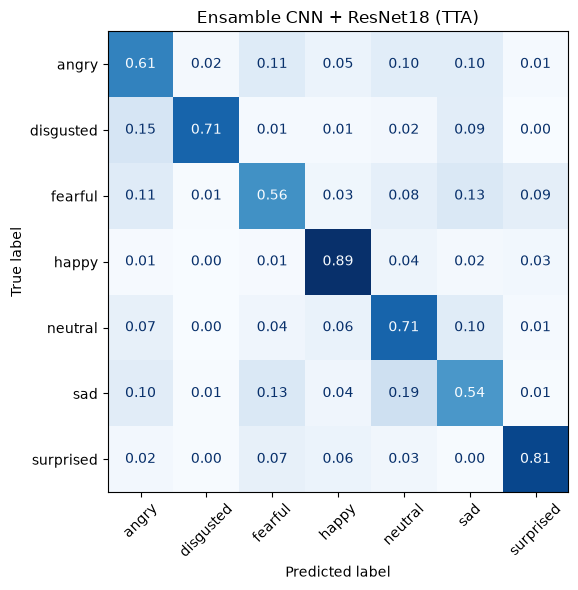

Diferencia de F1-macro frente al mejor modelo individual (CNN propia): +1.47 puntos porcentuales.


In [4]:
probabilities_by_model = {
    "CNN propia": probs_cnn,
    "ResNet18": probs_resnet,
    "Ensamble CNN + ResNet18": probs_ensemble,
}

rows = []
for model_name, probabilities in probabilities_by_model.items():
    predictions = probabilities.argmax(axis=1)
    rows.append({
        "modelo": model_name,
        "accuracy_pct": 100 * accuracy_score(y_val, predictions),
        "f1_macro_pct": 100 * f1_score(y_val, predictions, average="macro"),
    })

df_ensemble = pd.DataFrame(rows).round(2)
display(df_ensemble)

ensemble_predictions = probs_ensemble.argmax(axis=1)
print("\nInforme de clasificación — ensamble")
print(classification_report(y_val, ensemble_predictions, target_names=CLASS_NAMES, zero_division=0))

plot_confusion(y_val, ensemble_predictions, CLASS_NAMES, title="Ensamble CNN + ResNet18 (TTA)", figsize=(7, 6))

best_individual = max(rows[:2], key=lambda row: row["f1_macro_pct"])
difference = rows[2]["f1_macro_pct"] - best_individual["f1_macro_pct"]
print(
    f"Diferencia de F1-macro frente al mejor modelo individual "
    f"({best_individual['modelo']}): {difference:+.2f} puntos porcentuales."
)

### Análisis del ensamble (`CNNFer` + `ResNet-18`)
El ensamble combina las distribuciones de probabilidad *a posteriori* de ambos modelos mediante promediado uniforme (*soft voting*) con TTA horizontal:
$$P_{\text{ens}}(y \mid x) = \frac{1}{2}\left(P_{\text{CNNFer}}^{\text{TTA}}(y \mid x) + P_{\text{ResNet18}}^{\text{TTA}}(y \mid x)\right)$$

La complementariedad estructural entre una CNN compacta entrenada desde cero a resolución nativa ($48\times 48$) y una red residual preentrenada en ImageNet ($112\times 112$) reduce la varianza de los errores individuales, elevando el rendimiento en validación a **70.41 % de Accuracy** y **68.71 % de F1-macro** (**+1.47 puntos porcentuales** de F1-macro respecto al mejor modelo individual). La mejora se refleja de manera consistente en las clases con mayor ambigüedad emocional (`angry`, `fearful`, `sad` y `neutral`).
